# Ensemble on one sheet: v8-in + reader-v2 + the iter2 model

Each model predicts the sheet at its own resolution (v8-in and reader-v2 per pixel, the iter2 model per 16 px cell, repeated up to pixels, nothing is
downsampled). Every map is contrast-stretched to its own p1-p99.5 over the sheet mask; the ensemble combines the stretched maps with `SCORING`
('z-score' = mean of the per-model z-scores). `run_ensemble(sheet)` saves a 2x2 grid (three stretched model maps + the ensemble) at full resolution and
shows it at 1/10; each sheet has its own cell at the bottom.

Define the models, the sheets and the scoring in the first code cell, then run the rest. Predictions are cached under `output/ensemble/<sheet>/cache/`
(delete a file there to recompute that model). v8-in and reader-v2 run in their own virtualenvs as subprocesses; the iter2 model runs in this kernel.
All sheets are read the same way: v8-in on the central 24 layers, reader-v2 on its default centred 17-layer window, the iter2 model on a flat
depth-13 surface with window offset -1.

In [1]:
from pathlib import Path

# ---- sheets: name -> render zarr / mask id, and the flat-alias id (cached normalisation, stored cue map) -----------------------
SHEETS = {
    "auto_grown_20261012065803387_straightened2_abf": {"zid": "20261012065814", "norm_id": 20261012065815},
    "auto_grown_20261012065803387_REDO_abf": {"zid": "20261012065828", "norm_id": 20261012065829},
}

# ---- models: name -> settings ------------------------------------------------------------------------------------------
V8IN_RUN = Path("/vesuvius/nader-fork/runs/v8in_0846a_343/runs/v8in_0846a_343_6ep_20261021_013010_b2baf481/checkpoints")
MODELS = {
    # penultimate (5th) epoch of the 6-epoch v8-in fine-tune; epoch files are 0-based, so epochepoch=4
    "v8-in (fine-tune, epoch 5)": {"kind": "v8in", "checkpoint": V8IN_RUN / "epochepoch=4.ckpt", "batch_size": 4},
    # step 3200 of the reader-v2 fine-tune (not the 9600-step continuation)
    "reader-v2 (fine-tune, step 3200)": {"kind": "reader_v2", "checkpoint": "/vesuvius/reader-v2/runs/ft_0846a_343/ckpt_003200.pth"},
    # the iter2 model, read like 0846A_eval.ipynb: flat depth-13 surface, window offset -1, one depth
    "iter2 cue_dropout_labelsv3_seed17": {
        "kind": "iter2", "checkpoint": "/vesuvius/models/runs_iter2/iter2_cue_dropout_labelsv3_seed17/final.pth", "depth_offset": -1,
        "infer_batch": 4,
    },
}

# ---- scoring ----------------------------------------------------------------------------------------------------------
SCORING = "z-score"      # 'z-score' | 'mean' | 'rank'  (see SCORING_METHODS below)
STRETCH = (1.0, 99.5)    # percentiles of each model's map over the sheet mask

FLAT_DEPTH = 13
EVAL_STRIDE = 32         # iter2 inference stride (px)
PREVIEW_DOWNSCALE = 10   # the saved figure stays full size

In [2]:
import gc
import os
import subprocess
import sys
import types

import cv2
import numpy as np
import torch
import zarr
from IPython.display import display
from PIL import Image

REPO = Path("/vesuvius")
# nonml_ink.py (imported by utils.precomputed_asf) lives in old/
for _path in (REPO, REPO / "old"):
    if str(_path) not in sys.path:
        sys.path.insert(0, str(_path))
os.chdir(REPO)
Image.MAX_IMAGE_PIXELS = None

from utils.fast_figure import colorize, orient_display, save_panel_grid

ENSEMBLE_ROOT = REPO / "output" / "ensemble"
MODEL_CACHE = ENSEMBLE_ROOT / "_models"   # exported v8-in checkpoints, shared by all sheets


def slug(text):
    return "".join(ch if ch.isalnum() else "_" for ch in text).strip("_")


class Sheet:
    def __init__(self, name):
        spec = SHEETS[name]
        self.name, self.zid, self.norm_id = name, spec["zid"], spec["norm_id"]
        self.zarr_path = REPO / "ves_zarrs2" / f"{self.zid}.zarr"
        self.out_dir = ENSEMBLE_ROOT / name
        self.cache = self.out_dir / "cache"
        self.cache.mkdir(parents=True, exist_ok=True)
        self.mask = cv2.imread(str(REPO / "masks" / f"{self.zid}.png"), cv2.IMREAD_GRAYSCALE) > 0
        self.frame = self.mask.shape

    def to_frame(self, array):
        # map of any extent -> float32 frame, NaN outside the sheet mask
        out = np.full(self.frame, np.nan, np.float32)
        rows, cols = min(self.frame[0], array.shape[0]), min(self.frame[1], array.shape[1])
        out[:rows, :cols] = array[:rows, :cols]
        out[~self.mask] = np.nan
        return out

In [3]:
# ---- v8-in: runs in nader-fork's virtualenv (it needs safetensors); the central 24 layers of the sheet are its input ----------
FORK = REPO / "nader-fork"
V8IN_PREDICT = '''
import sys
import numpy as np
sys.path.insert(0, sys.argv[1])
from ink8um import InkDetector, predict_surface
model = InkDetector.from_pretrained(sys.argv[2])
prediction = predict_surface(model, sys.argv[3], reverse=model.reverse_layers, batch_size=int(sys.argv[5]))
np.save(sys.argv[4], prediction.astype(np.float16))
'''


def v8in_layers(sheet):
    existing = FORK / "runs" / "v8in_0846a_343" / "data_vis" / sheet.name / "layers"
    if (existing / "23.tif").is_file():
        return existing
    import tifffile

    folder = sheet.cache / "v8in_layers"
    folder.mkdir(exist_ok=True)
    volume = zarr.open(str(sheet.zarr_path), mode="r")
    start = (volume.shape[0] - 24) // 2
    for index in range(24):
        path = folder / f"{index:02d}.tif"
        if not path.is_file():
            tifffile.imwrite(path, np.clip(np.asarray(volume[start + index]), 0, 255).astype(np.uint8))
    return folder


def run_v8in(sheet, name, spec):
    prediction_path = sheet.cache / f"{slug(name)}.npy"
    if not prediction_path.is_file():
        python = str(FORK / ".venv" / "bin" / "python")
        model_dir = MODEL_CACHE / slug(name)
        if not (model_dir / "model.safetensors").is_file():
            subprocess.run([python, str(FORK / "training" / "export_checkpoint.py"), str(spec["checkpoint"]), str(model_dir)], check=True)
        subprocess.run([python, "-c", V8IN_PREDICT, str(FORK), str(model_dir), str(v8in_layers(sheet)), str(prediction_path),
                        str(spec.get("batch_size", 4))], check=True)
    return np.load(prediction_path).astype(np.float32)


# ---- reader-v2: the team's inference CLI in reader-v2's virtualenv (default centred 17-layer window, hann blend, overlap 0.5) --
def run_reader_v2(sheet, name, spec):
    tif = sheet.cache / f"{slug(name)}.tif"
    folder = REPO / "reader-v2"
    python = str(folder / ".venv" / "bin" / "python")
    if not tif.is_file():
        subprocess.run([python, "-m", "koine_machines.inference.infer", str(sheet.zarr_path), str(spec["checkpoint"]), str(tif),
                        "--overlap", "0.5", "--blend-mode", "hann", "--direction", "forward", "--no-compile"], cwd=folder, check=True)
    # the CLI writes an LZW tiff; imagecodecs lives in reader-v2's environment, so the uint8 map is converted to .npy there
    npy = tif.with_suffix(".npy")
    if not npy.is_file():
        subprocess.run([python, "-c", "import sys, numpy as np, tifffile; np.save(sys.argv[2], tifffile.imread(sys.argv[1]))",
                        str(tif), str(npy)], check=True)
    return np.load(npy).astype(np.float32) / 255.0


# ---- iter2 model: in this kernel, replaying the checkpoint's run config as 0846A_eval.ipynb does ------------------------------
def run_iter2(sheet, name, spec):
    path = sheet.cache / f"{slug(name)}.npz"
    if not path.is_file():
        from utils.config import Config, ScrollConfig, resolve_run_config
        from utils.model import create_model
        from utils.norm import UNIFIED_CACHE_PATH, load_cached_norm
        from utils.platform import get_zarr_dir
        from utils.visualizer import TensorboardVisualizer, predict_tiles

        checkpoint = Path(spec["checkpoint"]).resolve()
        run_config, _ = resolve_run_config(checkpoint)
        C = Config()
        for section in ("data", "model"):
            for key, value in run_config[section].items():
                if section == "data" and key == "scrolls":
                    C.data.scrolls = [ScrollConfig(**item) for item in value]
                elif key != "probe_rois" and hasattr(getattr(C, section), key):
                    setattr(getattr(C, section), key, value)
        C.model.compile_model = False
        C.tra.supcon = False
        C.tra.dann = False
        C.device = "cuda" if torch.cuda.is_available() else "cpu"
        C.data.eval_stride = EVAL_STRIDE
        C.data.eval_infer_bs = int(spec.get("infer_batch", 0))  # 0 = automatic; a small value saves VRAM, results are identical
        offset = int(spec.get("depth_offset", -1))
        C.data.surface_window_offset = offset
        C.data.surface_window_offset_by_scroll = {}
        C.data.zarr_path = str(Path(get_zarr_dir()))
        depth = int(C.data.depth)
        if depth != 8 or not C.model.surface_teacher_input or not C.data.surface_relative_depth_window:
            raise ValueError("Select a literal-surface, eight-slice checkpoint")
        model, _ = create_model(C)
        state = torch.load(checkpoint, map_location="cpu", weights_only=True)
        state = state.get("model_state_dict", state.get("state_dict", state))
        state = {key.removeprefix("module.").removeprefix("_orig_mod."): value for key, value in state.items()}
        state = {key: value for key, value in state.items() if not key.startswith(("supcon_head.", "domain_head."))}
        model.load_state_dict(state, strict=True)
        model.eval()

        volume = np.ascontiguousarray(zarr.open(str(sheet.zarr_path), mode="r")[:])
        volume.setflags(write=False)
        height, width = sheet.mask.shape
        surface_depth = np.where(sheet.mask, FLAT_DEPTH, 255).astype(np.uint8)
        surface_confidence = np.where(sheet.mask, 255, 0).astype(np.uint8)
        norm = load_cached_norm(sheet.norm_id, UNIFIED_CACHE_PATH, mode=str(C.data.norm_mode))
        if norm is None:
            raise RuntimeError(f"no cached normalisation for {sheet.norm_id}")
        cue = None
        if str(C.model.input_cue) == "pre_clahe":
            cue = np.load(Path(C.data.cue_dir) / f"{sheet.norm_id}.npy", mmap_mode="r")
        coords = TensorboardVisualizer._gen_tile_coords(
            types.SimpleNamespace(c=C), (C.data.d_start, C.data.d_end), (0, height), (0, width), sheet.mask, z_step=depth,
        )
        grid = predict_tiles(
            C, model, volume, sheet.mask, coords, (0, height), (0, width), C.data.d_start, sheet.name, *norm,
            surface_depth_map=surface_depth, surface_confidence_map=surface_confidence,
            surface_depth_offset=offset, cue_map=cue,
        )
        np.savez(path, grid=np.asarray(grid, dtype=np.float32), cell=int(C.model.multitile_subtile))
        del model, volume
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    saved = np.load(path)
    cell = int(saved["cell"])
    return np.repeat(np.repeat(saved["grid"], cell, axis=0), cell, axis=1)


RUNNERS = {"v8in": run_v8in, "reader_v2": run_reader_v2, "iter2": run_iter2}

In [4]:
# ---- stretching and scoring ----------------------------------------------------------------------------------------------
def stretch(prediction, mask):
    valid = mask & np.isfinite(prediction)
    low, high = np.percentile(prediction[valid], STRETCH)
    stretched = np.clip((prediction - low) / max(float(high - low), 1e-6), 0, 1)
    return np.where(valid, stretched, np.nan).astype(np.float32), float(low), float(high)


def z_score(values):
    valid = np.isfinite(values)
    return ((values - values[valid].mean()) / max(float(values[valid].std()), 1e-6)).astype(np.float32)


def rank_score(values):
    valid = np.isfinite(values)
    ranks = np.full(values.shape, np.nan, np.float32)
    order = np.argsort(values[valid], kind="stable")
    scores = np.empty(order.size, np.float32)
    scores[order] = np.linspace(0, 1, order.size, dtype=np.float32)
    ranks[valid] = scores
    return ranks


# stretched maps (list) -> ensemble map; every method returns NaN outside the sheet
SCORING_METHODS = {
    "z-score": lambda maps: np.mean([z_score(m) for m in maps], axis=0),
    "mean": lambda maps: np.mean(maps, axis=0),
    "rank": lambda maps: np.mean([rank_score(m) for m in maps], axis=0),
}
if SCORING not in SCORING_METHODS:
    raise ValueError(f"SCORING must be one of {sorted(SCORING_METHODS)}")


def run_ensemble(sheet_name):
    # run every model on the sheet, stretch, combine, save the 2x2 grid at full resolution, show it at 1/10
    sheet = Sheet(sheet_name)
    print(f"{sheet.name}: frame {sheet.frame}, {int(sheet.mask.sum()):,} papyrus pixels; cache {sheet.cache}")
    stretched, limits = {}, {}
    for name, spec in MODELS.items():
        print(f"[{spec['kind']}] {name}")
        stretched[name], low, high = stretch(sheet.to_frame(RUNNERS[spec["kind"]](sheet, name, spec)), sheet.mask)
        limits[name] = (low, high)
        print(f"    p{STRETCH[0]:g} {low:.4f}, p{STRETCH[1]:g} {high:.4f}")
        gc.collect()

    ensemble = SCORING_METHODS[SCORING](list(stretched.values()))
    valid = np.isfinite(ensemble)
    e_low, e_high = np.percentile(ensemble[valid], STRETCH)
    print(f"ensemble ({SCORING}): p{STRETCH[0]:g} {e_low:.3f}, p{STRETCH[1]:g} {e_high:.3f}")

    bad = (0.78, 0.86, 0.95)
    panels = [
        (f"{name} | stretched p{STRETCH[0]:g}-p{STRETCH[1]:g} ({limits[name][0]:.3f}..{limits[name][1]:.3f})",
         colorize(orient_display(array, sheet.name), "gray_r", bad), cv2.INTER_AREA, None)
        for name, array in stretched.items()
    ]
    panels.append((f"ensemble | mean of per-model {SCORING}s, shown p{STRETCH[0]:g}-p{STRETCH[1]:g}",
                   colorize(orient_display(ensemble, sheet.name), "gray_r", bad, vmin=float(e_low), vmax=float(e_high)),
                   cv2.INTER_AREA, None))
    cell_hw = orient_display(ensemble, sheet.name).shape

    grid_path = sheet.out_dir / f"ensemble_{slug(SCORING)}_2x2.png"
    save_panel_grid([panels[:2], panels[2:]], cell_hw, str(grid_path), gap_px=24)
    np.save(sheet.out_dir / f"ensemble_{slug(SCORING)}.npy", ensemble.astype(np.float16))
    print(f"Saved {grid_path}")
    with Image.open(grid_path) as saved:
        print("full size", saved.size)
        display(saved.resize((max(1, saved.width // PREVIEW_DOWNSCALE), max(1, saved.height // PREVIEW_DOWNSCALE)),
                             Image.Resampling.LANCZOS))
    del stretched, ensemble, panels
    gc.collect()
    return grid_path

auto_grown_20261012065803387_straightened2_abf: frame (2561, 4101), 7,602,644 papyrus pixels; cache /vesuvius/output/ensemble/auto_grown_20261012065803387_straightened2_abf/cache
[v8in] v8-in (fine-tune, epoch 5)
    p1 0.0000, p99.5 0.4937
[reader_v2] reader-v2 (fine-tune, step 3200)
    p1 0.2353, p99.5 0.5137
[iter2] iter2 cue_dropout_labelsv3_seed17
    p1 0.0082, p99.5 0.9429
ensemble (z-score): p1 -1.608, p99.5 3.263
Saved /vesuvius/output/ensemble/auto_grown_20261012065803387_straightened2_abf/ensemble_z_score_2x2.png
full size (8508, 5792)


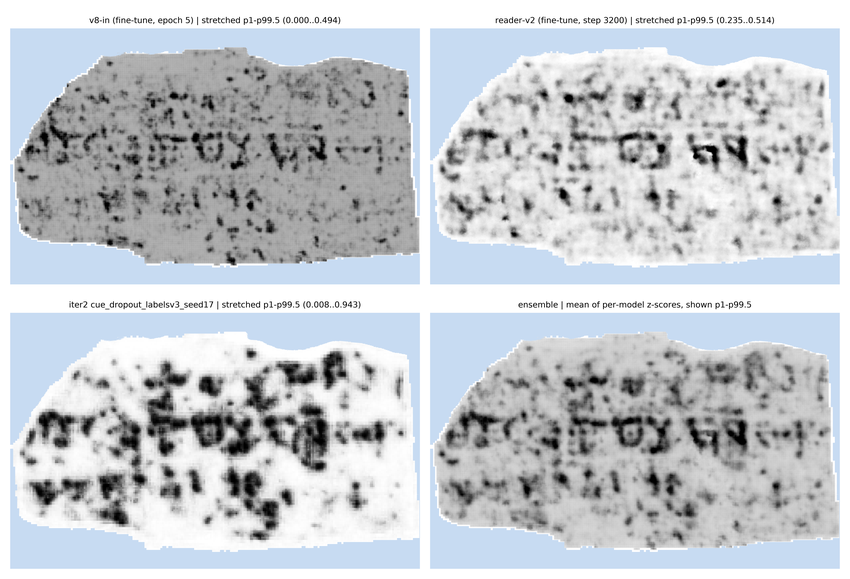

In [5]:
# straightened2 (held-out winning sheet)
straightened2_path = run_ensemble("auto_grown_20261012065803387_straightened2_abf")

auto_grown_20261012065803387_REDO_abf: frame (3381, 4841), 8,548,119 papyrus pixels; cache /vesuvius/output/ensemble/auto_grown_20261012065803387_REDO_abf/cache
[v8in] v8-in (fine-tune, epoch 5)
    p1 0.0000, p99.5 0.4976
[reader_v2] reader-v2 (fine-tune, step 3200)
    p1 0.2314, p99.5 0.5098
[iter2] iter2 cue_dropout_labelsv3_seed17


2026-10-21 23:18:02.605983: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-21 23:18:02.607595: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-21 23:18:02.610629: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-21 23:18:02.616223: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1792624682.624546  926020 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1792624682.62

Model parameters (nnunet3d_lcndz): 7,554,654


/usr/local/lib/python3.10/dist-packages/torch/_utils.py:831: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()


[predict] reading 8476 tiles in 98 row-strips (auto_grown_20261012065803387_REDO_abf)


Predict chunk: 100%|█████████▉| 448/450 [00:17<00:00, 26.14it/s]


[predict] auto_grown_20261012065803387_REDO_abf done in  86.5s  predict  83.5s (96.6%)  read/wait   2.9s ( 3.4%)  [prefetch x3]
    p1 0.0083, p99.5 0.9460
ensemble (z-score): p1 -1.623, p99.5 3.297
Saved /vesuvius/output/ensemble/auto_grown_20261012065803387_REDO_abf/ensemble_z_score_2x2.png
full size (10045, 7607)


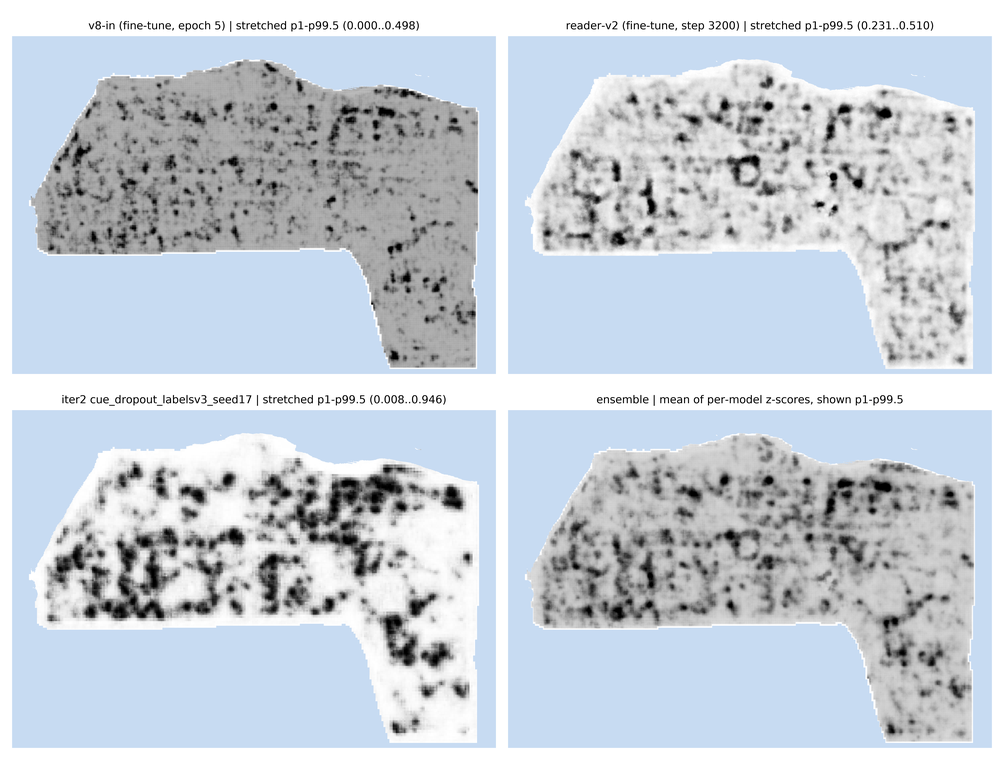

In [6]:
# REDO sheet
redo_path = run_ensemble("auto_grown_20261012065803387_REDO_abf")